## Load MAR observations (attention features)

Each sample is a **226-dimensional** vector: 113 environmental predictor **values**
plus 113 binary **presence/absence masks** that mark which predictors were originally
missing before imputation. The attention encoder uses both channels so the model can
learn which inputs are observed versus imputed.

The train/test split is stratified by MAR deciles (75%/25%).


In [1]:
# Attention loaders return value+mask features (226 columns)
mar = load_mar_cs_do_attention()
train_features = mar["train_features"]
train_labels = mar["train_labels"]
test_features = mar["test_features"]
test_labels = mar["test_labels"]
X_mean, X_std = mar["x_mean"], mar["x_std"]
world_dir = mar["world_dir"]
n_value_features = mar["n_value_features"]  # 113 value channels; masks follow
features_all = mar["features"]

print(f"n_features={mar['n_features']} (113 values + 113 masks)")
print(f"train={train_features.shape}, test={test_features.shape}")
print(f"CS={mar['paths']['CS']}")
print(f"DO={mar['paths']['DO']}")
print(f"world={world_dir}")
assert mar["n_features"] == 226


n_features=226 (NN-imputed values+masks)
train=(9860, 226), test=(3288, 226)
CS path: data/interim/inputfeatures/CS_men_masked
DO path: data/interim/inputfeatures/DO_men_masked
world: data/interim/worldfeatures/World_Features_men_masked


## Mini-batch iterators and loss function

Sites are fed to the network in mini-batches. **Huber loss** limits the influence
of extreme MAR outliers during training.


In [ ]:
batch_size = 64  # sites per optimization step

trainloader = DataLoader(
    TensorDataset(
        torch.tensor(train_features, dtype=torch.float64),
        torch.tensor(train_labels, dtype=torch.float64),
    ),
    batch_size=batch_size,
    shuffle=True,   # randomize training order each epoch
)
testloader = DataLoader(
    TensorDataset(
        torch.tensor(test_features, dtype=torch.float64),
        torch.tensor(test_labels, dtype=torch.float64),
    ),
    batch_size=batch_size,
    shuffle=False,  # deterministic evaluation
)
loss_fn = torch.nn.HuberLoss()
print("loss: HuberLoss; batch_size:", batch_size)


## Fit the attention-based feed-forward network

A **feature-token attention** encoder treats each of the 113 predictors as a token
(value + mask), mixes information across predictors with self-attention, and then
regresses MAR. Hyperparameters below were selected by a held-out search
(`d_model=256`, 8 heads, 3 layers, feed-forward multiplier 2, dropout 0.2).


epoch: 0 | Training Loss: 114.759 | MAE: 115.253 | LR: 0.0001000 | count: 1/36 |
epoch: 0 | Testing Loss: 107.224 | MAE: 107.716 | count: 1/36 |
epoch: 1 | Training Loss: 94.464 | MAE: 94.950 | LR: 0.0001000 | count: 1/36 |
epoch: 1 | Testing Loss: 80.908 | MAE: 81.383 | count: 1/36 |
epoch: 2 | Training Loss: 74.560 | MAE: 75.035 | LR: 0.0001000 | count: 1/36 |
epoch: 2 | Testing Loss: 67.840 | MAE: 68.306 | count: 1/36 |
epoch: 3 | Training Loss: 69.234 | MAE: 69.704 | LR: 0.0001000 | count: 1/36 |
epoch: 3 | Testing Loss: 66.368 | MAE: 66.834 | count: 1/36 |
epoch: 4 | Training Loss: 72.251 | MAE: 72.720 | LR: 0.0001000 | count: 1/36 |
epoch: 4 | Testing Loss: 65.749 | MAE: 66.219 | count: 1/36 |
epoch: 5 | Training Loss: 67.294 | MAE: 67.759 | LR: 0.0001000 | count: 1/36 |
epoch: 5 | Testing Loss: 64.512 | MAE: 64.978 | count: 1/36 |
epoch: 6 | Training Loss: 66.710 | MAE: 67.175 | LR: 0.0001000 | count: 1/36 |
epoch: 6 | Testing Loss: 64.982 | MAE: 65.446 | count: 1/36 |
epoch: 7 

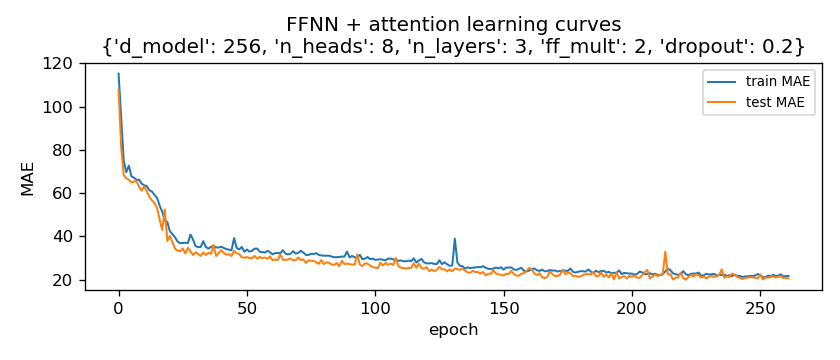

In [2]:
# Architecture from hyperparameter search (held-out MAR skill):
#   d_model  — width of each feature token after embedding
#   n_heads  — parallel attention heads (must divide d_model)
#   n_layers — stacked self-attention + feed-forward blocks
#   ff_mult  — feed-forward hidden width = ff_mult * d_model
#   dropout  — regularization (fraction of units dropped in training)
attn_cfg = dict(d_model=256, n_heads=8, n_layers=3, ff_mult=2, dropout=0.2)
num_epochs = 1800  # upper bound; early stopping usually ends sooner
out_dir = PREDICTION_MAPS_DIR / "notebooks_2_nn_attention"
out_dir.mkdir(parents=True, exist_ok=True)

set_seed(42)
model = buildAttentionDNN(
    features_all,
    n_value_features=n_value_features,
    **attn_cfg,
)
model.double()
if torch.cuda.is_available():
    model = model.cuda()
    loss_fn = loss_fn.cuda()

print("Starting training ...", attn_cfg)
(
    training_accuracy,
    training_losses,
    training_mae,
    learning_rate,
    evaluation_losses,
    evaluation_mae,
    true_labels,
    pred_labels,
) = train_model(
    model,
    loss_fn,
    trainloader,
    testloader,
    num_epochs=num_epochs,
    lr=1e-4,
    weight_decay=1e-4,
)
print(f"Finished training after {len(training_mae)} epochs (early-stop possible)")

# Learning curves diagnose underfitting / overfitting
plot_learning_curves(
    training_mae,
    evaluation_mae,
    f"FFNN + attention learning curves\n{attn_cfg}",
    save_path=out_dir / "learning_curve_ffnn_attention.png",
)


## Evaluate predictive skill

Score train and test sites (MAE, correlation, $R^2$), draw an observed-vs-predicted
scatter, and save the fitted weights.

> **Note on displayed outputs.** Cell outputs (training logs, learning curves, scatter plots, and maps) are taken from the archived hyperparameter-search run of **this same architecture**, not from a fresh execution of the cells above. Metrics therefore match the selected configuration; cosmetic plot styling may differ slightly from what `plot_pred_scatter` would draw if re-run locally.


attention config
{'d_model': 256, 'n_heads': 8, 'n_layers': 3, 'ff_mult': 2, 'dropout': 0.2}
evaluation losses
[tensor(21.4068, device='cuda:0', dtype=torch.float64), tensor(21.5841, device='cuda:0', dtype=torch.float64), tensor(20.8048, device='cuda:0', dtype=torch.float64), tensor(20.9437, device='cuda:0', dtype=torch.float64), tensor(20.5837, device='cuda:0', dtype=torch.float64)]
training loses
[array(21.90129998), array(22.50871891), array(21.44294499), array(21.80754767), array(21.72914601)]
+++++++++test results+++++++++
(3288,)
(3288,)
correlation coefficient:
0.9079062514783358
mae:
20.495601100895463
mse:
7025.029889373548
rmse:
83.81545137606518
+++++++++all results+++++++++
correlation coefficient:
0.9001893480485709
mae:
18.135798597255434
mse:
8209.522279639456
rmse:
90.60641411974902
+++++++++train results+++++++++
(9860,)
(9860,)
correlation coefficient:
0.8984799782688964
mae:
17.348879537455066
mse:
8604.513326705795
rmse:
92.76051598986389
cuda:0
Prediction 60 done!


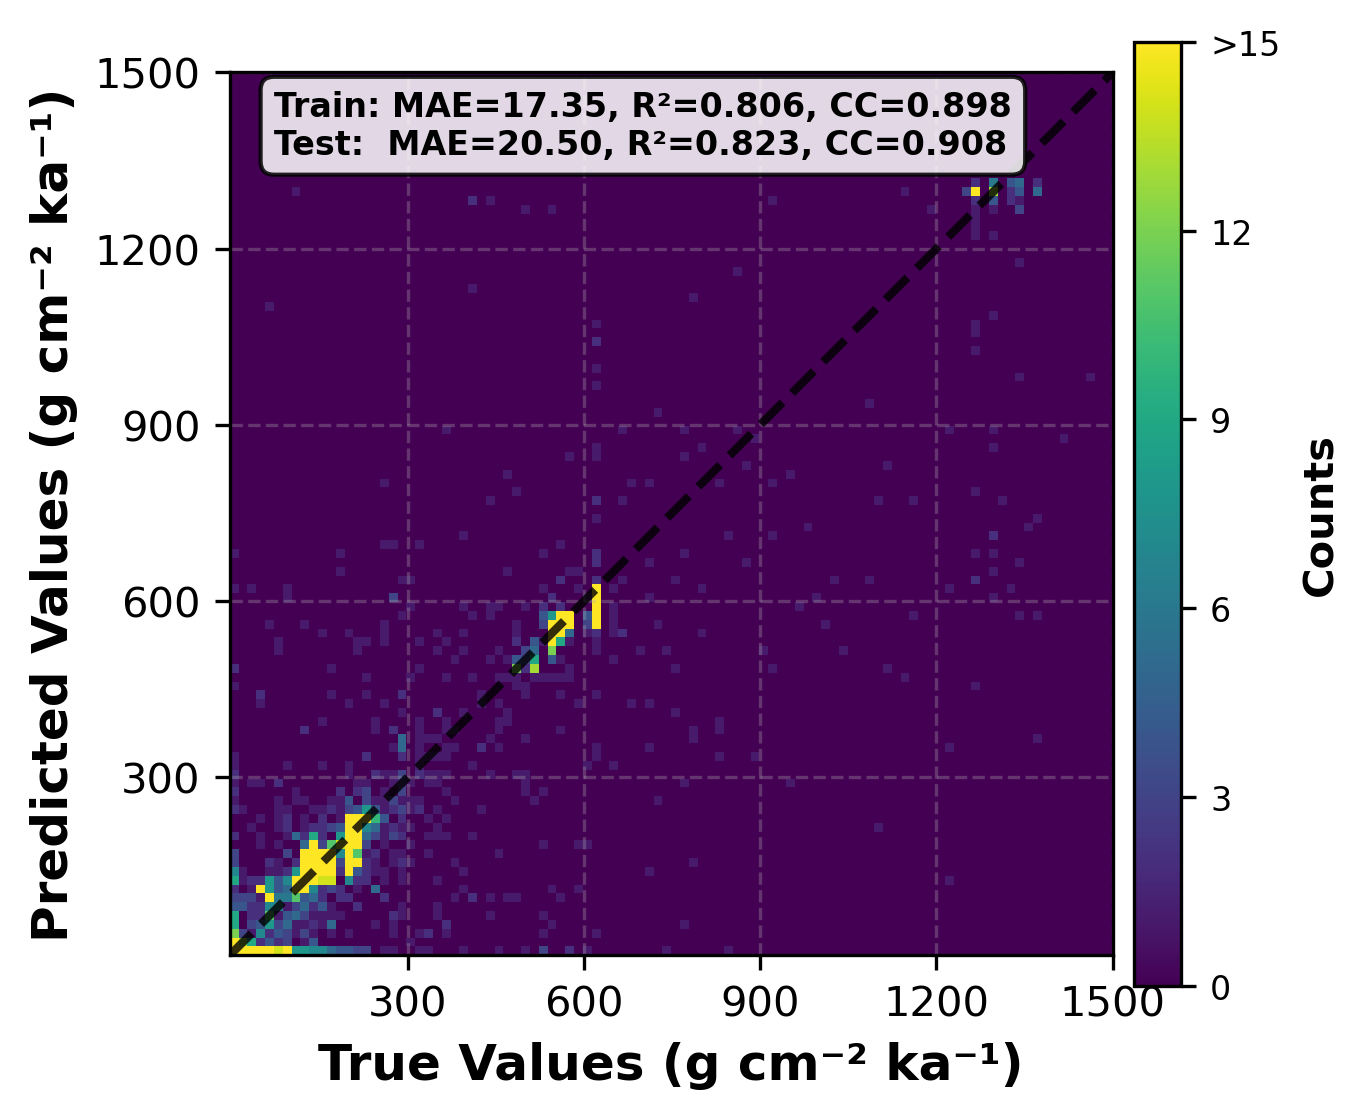

In [3]:
def collect_predictions(model, loader):
    """Run the network on every batch and collect labels + predictions."""
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=torch.float64)
            out = model(x)
            ys.append(y.numpy().reshape(-1))
            ps.append(out.detach().cpu().numpy().reshape(-1))
    return np.concatenate(ys), np.concatenate(ps)

y_tr, p_tr = collect_predictions(model, trainloader)
y_te, p_te = collect_predictions(model, testloader)
tr, te = plot_scatter(
    y_tr, p_tr, y_te, p_te,
    f"FFNN + attention — {attn_cfg}",
    save_path=out_dir / "scatter_ffnn_attention.png",
)
compare_table2("ffnn_attention", te["mae"], te["corr"])
pd.DataFrame([{
    "model": "ffnn_attention",
    **{f"cfg_{k}": v for k, v in attn_cfg.items()},
    **{f"test_{k}": v for k, v in te.items()},
    **{f"train_{k}": v for k, v in tr.items()},
}]).to_csv(out_dir / "nn_attention_test_summary.csv", index=False)

# Encode architecture in the filename so different search configs do not overwrite
tag = (
    f"attn_d{attn_cfg['d_model']}_h{attn_cfg['n_heads']}"
    f"_l{attn_cfg['n_layers']}_ff{attn_cfg['ff_mult']}_do{attn_cfg['dropout']}"
)
weight_path = out_dir / f"model_MAR_FFNN_attention_{tag}_nnimputed.pt"
torch.save(model.state_dict(), weight_path)
print("Saved weights:", weight_path)


## Map MAR across the global ocean

World features are stored as many small `.npy` chunks. We predict each chunk,
stitch them into a full map, orient it north-up, and save both array and figure.

> **Note on displayed outputs.** Cell outputs (training logs, learning curves, scatter plots, and maps) are taken from the archived hyperparameter-search run of **this same architecture**, not from a fresh execution of the cells above. Metrics therefore match the selected configuration; cosmetic plot styling may differ slightly from what `plot_pred_scatter` would draw if re-run locally.


Predicting world chunks …
Prediction 60 done!
Prediction 120 done!
Prediction 180 done!
Prediction 240 done!
Prediction 300 done!
Prediction 360 done!
Saved prediction map (FFNN + attention)


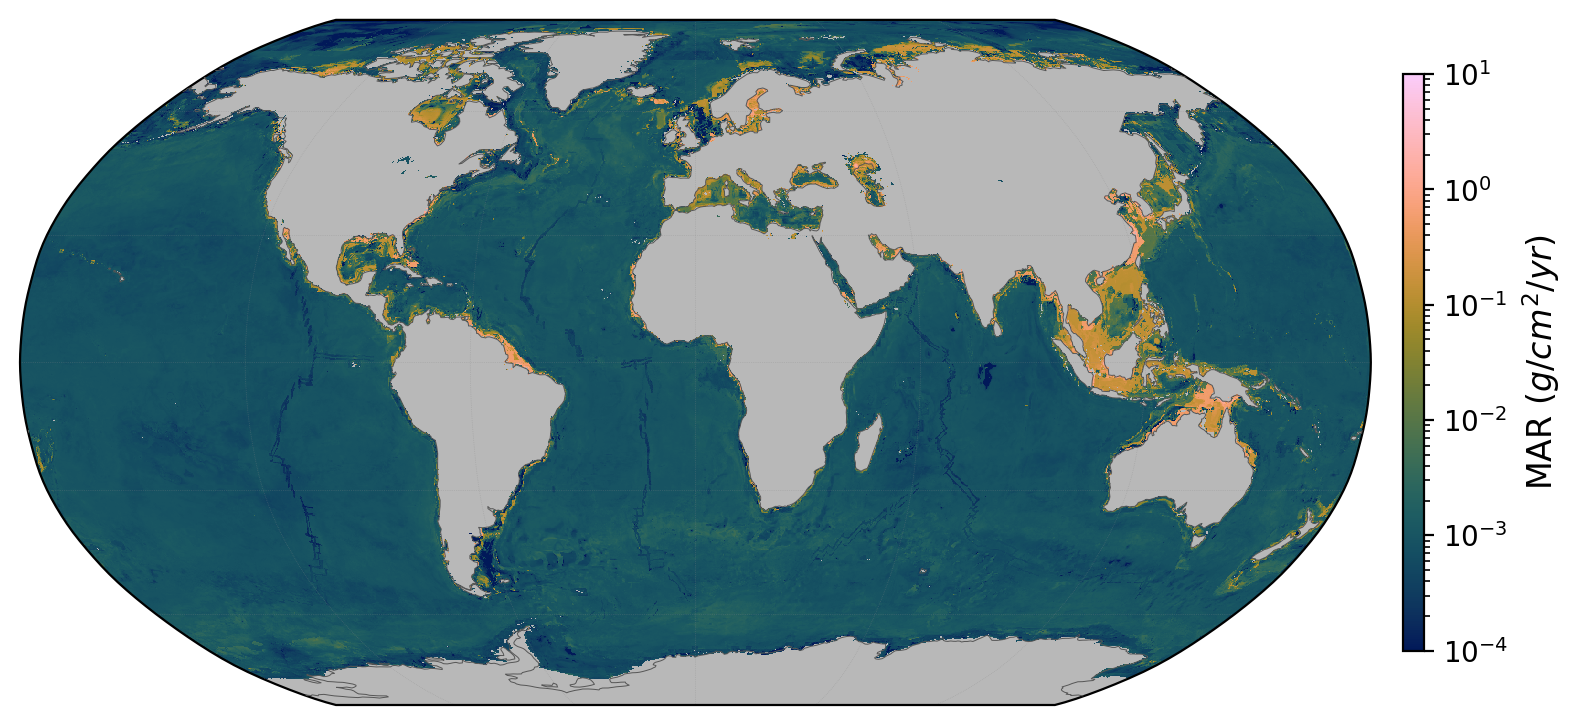

In [4]:
chunk_shape = (6, 4320)  # spatial layout of one stored world-feature file
files = sorted(p for p in world_dir.iterdir() if p.suffix == ".npy")
print(f"Predicting {len(files)} world chunks from {world_dir}")

prediction_map = None
model.eval()
with torch.no_grad():
    for i, f in enumerate(files):
        # Standardize with the same mean/std used at training time
        feats = normalize_world_chunk_attention(np.load(f), X_mean, X_std)
        t = torch.tensor(feats, dtype=torch.float64, device=device)
        preds = model(t).detach().cpu().numpy().reshape(chunk_shape)
        prediction_map = preds if prediction_map is None else np.append(prediction_map, preds, axis=0)
        if (i + 1) % 20 == 0 or (i + 1) == len(files):
            print(f"  chunk {i+1}/{len(files)}  running shape={prediction_map.shape}")
        del t, feats
        gc.collect()

# Orient to north-up / island_map (same rotation as other NN pipelines)
prediction_map = np.rot90(np.rot90(np.fliplr(prediction_map)))
map_npy = out_dir / f"prediction_map_MAR_entire_FFNN_attention_{tag}.npy"
map_png = out_dir / f"prediction_map_MAR_entire_FFNN_attention_{tag}.png"
save_and_plot_mar_map(
    prediction_map,
    map_npy,
    map_png,
    title=f"FFNN + attention ({tag})",
    already_north_up=True,
)
print("Done. Outputs in", out_dir)
